# Lab Exercise-7: Pandas 
Q6: Demonstrate Pandas with its operations
Develop a generic Python program to process, wrangle, transform, aggregate, and visualize
your domain-specific dataset (e.g., CSV, Excel, or DataFrame structure). Your program must
utilize the concepts outlined in the Pandas Cheat Sheet to perform the following core data
processing tasks:


In [35]:
import pandas as pd

# Configure global Pandas display options (Task 7a)
pd.set_option('display.max_rows', 12)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 2)
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.colheader_justify', 'center')

print("Global Pandas display options configured successfully.")

Global Pandas display options configured successfully.


## 1. Dataset Inspection & Type Handling
* Load dataset using `pd.read_csv()`.
* Inspect `.shape`, `.memory_usage()`, `.dtypes`, `.info()`, and `.describe()`.
* Perform explicit type conversions using `pd.to_numeric()`, `pd.to_datetime()`, `.astype()`, and `.infer_objects()`.

In [36]:
df = pd.read_csv('data.csv')

print("Initial Shape (Rows, Columns): {}".format(df.shape))
print("Total Memory Usage (Bytes): {:,}".format(df.memory_usage().sum()))
print("\nInitial Data Types:\n{}".format(df.dtypes))
print("\nDataFrame Concise Info:")
df.info()

Initial Shape (Rows, Columns): (11914, 16)
Total Memory Usage (Bytes): 1,525,120

Initial Data Types:
Make                 object
Model                object
Year                  int64
Engine Fuel Type     object
Engine HP           float64
                     ...   
Vehicle Style        object
highway MPG           int64
city mpg              int64
Popularity            int64
MSRP                  int64
Length: 16, dtype: object

DataFrame Concise Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object

In [37]:
# Explicit Type Conversions
df['Engine HP'] = pd.to_numeric(df['Engine HP'], errors='coerce')
df['Release_Date'] = pd.to_datetime(df['Year'].astype(str) + '-06-15')
df['Vehicle Size'] = df['Vehicle Size'].astype('category')
df = df.infer_objects()

print("Updated Data Types (Engine HP, Release_Date, Vehicle Size):")
print(df[['Engine HP', 'Release_Date', 'Vehicle Size']].dtypes)

# Display descriptive statistics
df.describe()

Updated Data Types (Engine HP, Release_Date, Vehicle Size):
Engine HP              float64
Release_Date    datetime64[ns]
Vehicle Size          category
dtype: object


,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.00,11845.00,11884.00,11908.00,11914.00,11914.00,11914.00,1.19e+04
mean,2010.38,249.39,5.63,3.44,26.64,19.73,1554.91,4.06e+04
std,7.58,109.19,1.78,0.88,8.86,8.99,1441.86,6.01e+04
min,1990.00,55.00,0.00,2.00,12.00,7.00,2.00,2.00e+03
25%,2007.00,170.00,4.00,2.00,22.00,16.00,549.00,2.10e+04
50%,2015.00,227.00,6.00,4.00,26.00,18.00,1385.00,3.00e+04
75%,2016.00,300.00,6.00,4.00,30.00,22.00,2009.00,4.22e+04
max,2017.00,1001.00,16.00,4.00,354.00,137.00,5657.00,2.07e+06


**Interpretation (Task 1):** The dataset contains **11,914 rows and 16 columns**, consuming **1,525,120 bytes (~1.52 MB)** of memory. Converting `Vehicle Size` to `category` optimizes memory, while `pd.to_datetime()` constructs a valid `datetime64[ns]` column (`Release_Date`) for temporal extraction.

## 2. Data Cleaning & Reshaping (Task 3)
* Detect and handle missing values using `.isnull()`, `.dropna()`, `.fillna()`, `.ffill()`, and `.bfill()`.
* Remove duplicate records using `.drop_duplicates()`.
* Reshape layout using `pd.melt()`, `.pivot()`, `.T`, `.sort_values()`, `.sort_index()`, and **Method Chaining** (combining 4 methods in one statement).

In [38]:
print("Missing Values Per Column Before Cleaning:\n{}".format(
    df.isnull().sum()[df.isnull().sum() > 0]
))

# Demonstrate dropna() on a temporary view
dropped_na_sample = df.dropna()
print("\nRows remaining if all NaNs are dropped via dropna(): {}".format(len(dropped_na_sample)))

# Handle missing values using fillna(), ffill(), and bfill()
df['Engine HP'] = df['Engine HP'].fillna(df['Engine HP'].median())
df['Engine Cylinders'] = df['Engine Cylinders'].fillna(df['Engine Cylinders'].median())
df['Number of Doors'] = df['Number of Doors'].ffill().bfill()
df['Engine Fuel Type'] = df['Engine Fuel Type'].fillna('Unknown')
df['Market Category'] = df['Market Category'].fillna('Standard')

print("Total Missing Values After Cleaning: {}".format(df.isnull().sum().sum()))

# Remove duplicates
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Shape After Removing {} Duplicate Records: {}".format(
    len(df) - len(df_clean), df_clean.shape
))

Missing Values Per Column Before Cleaning:
Engine Fuel Type       3
Engine HP             69
Engine Cylinders      30
Number of Doors        6
Market Category     3742
dtype: int64

Rows remaining if all NaNs are dropped via dropna(): 8084
Total Missing Values After Cleaning: 0
Shape After Removing 715 Duplicate Records: (11199, 17)


In [39]:
# Method Chaining: Combining 4 methods (pd.melt -> .rename -> .query -> .sort_values)
melted_efficiency = (
    pd.melt(df_clean.head(50), id_vars=['Make', 'Model'], value_vars=['highway MPG', 'city mpg'])
    .rename(columns={'variable': 'MPG_Metric', 'value': 'MPG_Rating'})
    .query('MPG_Rating >= 25')
    .sort_values(by='MPG_Rating', ascending=False)
)
print("Method Chaining + pd.melt() Result (Top 5):")
display(melted_efficiency.head(5))

# Pivoting (.pivot()), Sorting Index (.sort_index()), and Transposing (.T)
pivoted_msrp = (
    df_clean.groupby(['Vehicle Size', 'Transmission Type'], observed=False)['MSRP']
    .mean()
    .reset_index()
    .pivot(index='Vehicle Size', columns='Transmission Type', values='MSRP')
    .sort_index()
)
print("\nPivoted Table (Mean MSRP by Vehicle Size & Transmission):")
display(pivoted_msrp)

print("\nTransposed Table (.T):")
display(pivoted_msrp.T)

Method Chaining + pd.melt() Result (Top 5):


,Make,Model,MPG_Metric,MPG_Rating
27,FIAT,124 Spider,highway MPG,35
39,BMW,2 Series,highway MPG,35
36,BMW,2 Series,highway MPG,35
29,FIAT,124 Spider,highway MPG,35
28,FIAT,124 Spider,highway MPG,35



Pivoted Table (Mean MSRP by Vehicle Size & Transmission):


Transmission Type,AUTOMATED_MANUAL,AUTOMATIC,DIRECT_DRIVE,MANUAL,UNKNOWN
Vehicle Size,,,,,
Compact,108995.01,28072.04,32894.22,29382.75,2247.33
Large,144656.95,57591.59,85255.56,11338.87,2000.00
Midsize,98524.21,38793.37,41009.00,31326.48,5658.00



Transposed Table (.T):


Vehicle Size,Compact,Large,Midsize
Transmission Type,,,
AUTOMATED_MANUAL,108995.01,144656.95,98524.21
AUTOMATIC,28072.04,57591.59,38793.37
DIRECT_DRIVE,32894.22,85255.56,41009.00
MANUAL,29382.75,11338.87,31326.48
UNKNOWN,2247.33,2000.00,5658.00


**Interpretation (Task 3):** A total of **3,850 missing values** across 5 columns were imputed using median imputation for numerical features and forward/backward fill (`ffill`/`bfill`) for door counts. Removing **715 exact duplicates** yielded **11,199 unique vehicles**. Pivoting and transposing reveal that `AUTOMATED_MANUAL` transmissions in `Large` vehicles command the highest average MSRP ($144,656.95).

## 3. Subsetting & Data Filtering (Task 2)
* Row slicing using positional (`.iloc[]`, `.iat[]`) and label-based (`.loc[]`, `.at[]`) indexers.
* Multi-condition logical filtering using `&`, `|`, `~`, and `.query()`.
* Column subsetting with `.filter(regex=...)` and membership testing with `.isin()`.
* Extracting extreme records via `.nlargest()` and `.nsmallest()`.

In [40]:
print("Positional Slicing (.iloc[0:3, [0, 1, 2, 4, 15]]):")
display(df_clean.iloc[0:3, [0, 1, 2, 4, 15]])

print("Label Slicing (.loc[0:2, 'Make':'Engine HP']):")
display(df_clean.loc[0:2, 'Make':'Engine HP'])

print("Single Value Access -> .iat[0, 0]: {} | .at[0, 'Model']: {}".format(
    df_clean.iat[0, 0], df_clean.at[0, 'Model']
))

# Multi-condition logical filtering (&, |, ~)
perf_filter = df_clean[
    (df_clean['Engine HP'] > 300) &
    ((df_clean['Transmission Type'] == 'MANUAL') | (df_clean['Driven_Wheels'] == 'rear wheel drive')) &
    ~(df_clean['Vehicle Size'] == 'Large')
]
print("\nMulti-Condition Logical Filter (&, |, ~) Matched Rows: {}".format(len(perf_filter)))

# Filtering with .query()
eco_query = df_clean.query('`highway MPG` > 35 and MSRP < 30000')
print("Query Filter (.query()) Matched Rows: {}".format(len(eco_query)))

Positional Slicing (.iloc[0:3, [0, 1, 2, 4, 15]]):


,Make,Model,Year,Engine HP,MSRP
0,BMW,1 Series M,2011,335.0,46135
1,BMW,1 Series,2011,300.0,40650
2,BMW,1 Series,2011,300.0,36350


Label Slicing (.loc[0:2, 'Make':'Engine HP']):


,Make,Model,Year,Engine Fuel Type,Engine HP
0,BMW,1 Series M,2011,premium unleaded (required),335.0
1,BMW,1 Series,2011,premium unleaded (required),300.0
2,BMW,1 Series,2011,premium unleaded (required),300.0


Single Value Access -> .iat[0, 0]: BMW | .at[0, 'Model']: 1 Series M

Multi-Condition Logical Filter (&, |, ~) Matched Rows: 958
Query Filter (.query()) Matched Rows: 824


In [41]:
# Subset columns using Regular Expressions
regex_subset = df_clean.filter(regex='(?i)engine|mpg')
print("Columns Matched via filter(regex='(?i)engine|mpg'): {}".format(list(regex_subset.columns)))

# Membership testing using .isin()
selected_brands = df_clean[df_clean['Make'].isin(['BMW', 'Audi', 'Tesla', 'Toyota'])]
print("Rows Matched via .isin(['BMW', 'Audi', 'Tesla', 'Toyota']): {}".format(len(selected_brands)))

print("\nTop 3 Most Expensive Vehicles (nlargest):")
display(df_clean.nlargest(3, 'MSRP')[['Make', 'Model', 'Year', 'Engine HP', 'MSRP']])

print("\nBottom 3 Highway Fuel Efficiency Vehicles (nsmallest):")
display(df_clean.nsmallest(3, 'highway MPG')[['Make', 'Model', 'Year', 'highway MPG', 'MSRP']])

Columns Matched via filter(regex='(?i)engine|mpg'): ['Engine Fuel Type', 'Engine HP', 'Engine Cylinders', 'highway MPG', 'city mpg']
Rows Matched via .isin(['BMW', 'Audi', 'Tesla', 'Toyota']): 1382

Top 3 Most Expensive Vehicles (nlargest):


,Make,Model,Year,Engine HP,MSRP
10661,Bugatti,Veyron 16.4,2008,1001.0,2065902
10663,Bugatti,Veyron 16.4,2009,1001.0,1705769
7973,Lamborghini,Reventon,2008,650.0,1500000



Bottom 3 Highway Fuel Efficiency Vehicles (nsmallest):


,Make,Model,Year,highway MPG,MSRP
579,Ferrari,550,2001,12,248500
580,Ferrari,550,2001,12,205840
3374,Lamborghini,Diablo,2001,12,294900


**Interpretation (Task 2):** Logical filtering isolated **958 compact/midsize performance cars** (>300 HP with manual or RWD layouts), while `.query()` identified **824 affordable high-efficiency vehicles**. Extreme value extraction via `nlargest()` identified the **2008 Bugatti Veyron 16.4 ($2,065,902)** as the costliest vehicle, whereas `nsmallest()` flagged V12 supercars (**Ferrari 550, Lamborghini Diablo at 12 MPG**) as the least fuel-efficient.

## 4. Column Engineering & Group Aggregation (Task 4)
* Engineer new columns using `.assign()`, vectorized arithmetic, `pd.qcut()`, and `pd.cut()`.
* Group data using `.groupby()` and compute `.size()` and multi-metric `.agg()` (`count`, `mean`, `std`, `sum`).
* Apply window functions (`.rolling()`, `.expanding()`) and cumulative operations (`.cumsum()`, `.cummax()`).

In [42]:
# Column engineering via .assign() and vectorized operations
df_clean = df_clean.assign(
    Highway_KMPL=lambda x: (x['highway MPG'] * 0.425144).round(2),
    City_KMPL=lambda x: (x['city mpg'] * 0.425144).round(2),
    Price_Per_HP=lambda x: (x['MSRP'] / x['Engine HP']).round(2)
)

# Discretization / Binning via pd.qcut() and pd.cut()
df_clean['HP_Quartile_Tier'] = pd.qcut(
    df_clean['Engine HP'], q=4, labels=['Economy', 'Standard', 'Performance', 'Supercar']
)
df_clean['Price_Bracket'] = pd.cut(
    df_clean['MSRP'], bins=[0, 25000, 50000, 100000, 3000000],
    labels=['Budget', 'Mid-Range', 'Luxury', 'Exotic']
)

print("Engineered & Binned Columns Sample:")
display(df_clean[['Make', 'Model', 'Highway_KMPL', 'Price_Per_HP', 'HP_Quartile_Tier', 'Price_Bracket']].head(4))

print("\nGroup Sizes by Vehicle Size (.size()):")
print(df_clean.groupby('Vehicle Size', observed=False).size())

# Multi-metric aggregation via .agg()
style_agg = df_clean.groupby('Vehicle Style').agg(
    Count=('Model', 'count'),
    Mean_HP=('Engine HP', 'mean'),
    Std_HP=('Engine HP', 'std'),
    Total_MSRP=('MSRP', 'sum'),
    Avg_Hwy_KMPL=('Highway_KMPL', 'mean')
).sort_values(by='Count', ascending=False)

print("\nMulti-Metric GroupBy Aggregation by Vehicle Style (Top 5):")
display(style_agg.head(5))

Engineered & Binned Columns Sample:


,Make,Model,Highway_KMPL,Price_Per_HP,HP_Quartile_Tier,Price_Bracket
0,BMW,1 Series M,11.05,137.72,Supercar,Mid-Range
1,BMW,1 Series,11.90,135.50,Performance,Mid-Range
2,BMW,1 Series,11.90,121.17,Performance,Mid-Range
3,BMW,1 Series,11.90,128.04,Standard,Mid-Range



Group Sizes by Vehicle Size (.size()):
Vehicle Size
Compact    4395
Large      2683
Midsize    4121
dtype: int64

Multi-Metric GroupBy Aggregation by Vehicle Style (Top 5):


,Count,Mean_HP,Std_HP,Total_MSRP,Avg_Hwy_KMPL
Vehicle Style,,,,,
Sedan,2843,243.39,104.85,115033523,12.83
4dr SUV,2434,263.59,84.98,99137486,10.42
Coupe,1175,331.96,156.34,91174463,10.90
Convertible,741,322.51,149.73,65368643,10.83
4dr Hatchback,663,164.66,60.41,14862118,16.08


In [43]:
yearly_trend = df_clean.groupby('Year')[['MSRP', 'Highway_KMPL']].mean().sort_index()
yearly_trend['Rolling_3Yr_KMPL'] = yearly_trend['Highway_KMPL'].rolling(3).mean()
yearly_trend['Expanding_Mean_MSRP'] = yearly_trend['MSRP'].expanding().mean()
yearly_trend['CumSum_MSRP'] = yearly_trend['MSRP'].cumsum()
yearly_trend['CumMax_KMPL'] = yearly_trend['Highway_KMPL'].cummax()

print("Window (.rolling, .expanding) & Cumulative (.cumsum, .cummax) Operations (Last 6 Years):")
display(yearly_trend.tail(6))

Window (.rolling, .expanding) & Cumulative (.cumsum, .cummax) Operations (Last 6 Years):


,MSRP,Highway_KMPL,Rolling_3Yr_KMPL,Expanding_Mean_MSRP,CumSum_MSRP,CumMax_KMPL
Year,,,,,,
2012,61959.13,11.01,10.66,24463.13,562652.05,11.01
2013,51475.76,11.51,11.07,25588.66,614127.81,11.51
2014,65523.25,11.84,11.45,27186.04,679651.06,11.84
2015,47506.33,12.28,11.87,27967.59,727157.39,12.28
2016,47863.96,12.37,12.16,28704.49,775021.35,12.37
2017,42185.16,12.15,12.27,29185.95,817206.51,12.37


## 5. Vectorized String & Datetime Operations (Task 5)
* Clean and extract text attributes using `.str.title()`, `.str.len()`, `.str.replace()`, `.str.split()`, and `.str.get()`.
* Extract temporal components using `.dt.year`, `.dt.month`, `.dt.day`, and `.dt.quarter`.

In [44]:
# Vectorized String Operations
df_clean['Make_Title'] = df_clean['Make'].str.title()
df_clean['Model_Char_Len'] = df_clean['Model'].str.len()
df_clean['Fuel_Cleaned'] = (
    df_clean['Engine Fuel Type']
    .str.replace(r'\(.*\)', '', regex=True)
    .str.strip()
    .str.title()
)
df_clean['Primary_Market_Tag'] = df_clean['Market Category'].str.split(',').str.get(0)

# Vectorized Datetime Operations
df_clean['Rel_Year'] = df_clean['Release_Date'].dt.year
df_clean['Rel_Month'] = df_clean['Release_Date'].dt.month
df_clean['Rel_Day'] = df_clean['Release_Date'].dt.day
df_clean['Rel_Quarter'] = df_clean['Release_Date'].dt.quarter

display(df_clean[[
    'Make_Title', 'Model_Char_Len', 'Fuel_Cleaned',
    'Primary_Market_Tag', 'Rel_Year', 'Rel_Month', 'Rel_Quarter'
]].head(5))

,Make_Title,Model_Char_Len,Fuel_Cleaned,Primary_Market_Tag,Rel_Year,Rel_Month,Rel_Quarter
0,Bmw,10,Premium Unleaded,Factory Tuner,2011,6,2
1,Bmw,8,Premium Unleaded,Luxury,2011,6,2
2,Bmw,8,Premium Unleaded,Luxury,2011,6,2
3,Bmw,8,Premium Unleaded,Luxury,2011,6,2
4,Bmw,8,Premium Unleaded,Luxury,2011,6,2


## 6. Merging & Combining Data (Task 6)
* Relational joins (`pd.merge()` with `left` and `inner` joins) against a secondary manufacturer metadata lookup table.
* Row concatenation via `pd.concat()`.
* Set-like difference operation (`how='outer', indicator=True`) from the Pandas Cheat Sheet.

In [45]:
brand_lookup = pd.DataFrame({
    'Make': ['Chevrolet', 'Ford', 'Toyota', 'Honda', 'BMW', 'Audi', 'Volkswagen', 'Dodge'],
    'HQ_Country': ['USA', 'USA', 'Japan', 'Japan', 'Germany', 'Germany', 'Germany', 'USA'],
    'Fleet_Tier': ['Core', 'Core', 'Core', 'Standard', 'Luxury', 'Luxury', 'Standard', 'Performance']
})

left_joined = pd.merge(df_clean, brand_lookup, how='left', on='Make')
inner_joined = pd.merge(df_clean, brand_lookup, how='inner', on='Make')
print("Left Join Shape: {} | Inner Join Shape: {}".format(left_joined.shape, inner_joined.shape))

# Concatenation using pd.concat()
batch_a = df_clean.iloc[0:3, 0:4]
batch_b = df_clean.iloc[3:6, 0:4]
concatenated_batches = pd.concat([batch_a, batch_b], axis=0)
print("Concatenated DataFrame Shape (pd.concat): {}".format(concatenated_batches.shape))

# Set-like Difference Operation (Vehicles in Top 10 HP that are NOT in Top 10 MSRP)
top_10_hp = df_clean.nlargest(10, 'Engine HP')[['Make', 'Model', 'Year', 'MSRP']]
top_10_msrp = df_clean.nlargest(10, 'MSRP')[['Make', 'Model', 'Year', 'MSRP']]

set_diff_vehicles = (
    pd.merge(top_10_hp, top_10_msrp, how='outer', indicator=True)
    .query('_merge == "left_only"')
    .drop(columns=['_merge'])
)
print("\nSet-Difference (In Top 10 HP but NOT in Top 10 MSRP):")
display(set_diff_vehicles)

Left Join Shape: (11199, 32) | Inner Join Shape: (4802, 32)
Concatenated DataFrame Shape (pd.concat): (6, 4)

Set-Difference (In Top 10 HP but NOT in Top 10 MSRP):


,Make,Model,Year,MSRP
4,Lamborghini,Aventador,2016,490700
5,Ferrari,F12 Berlinetta,2013,315888
6,Ferrari,F12 Berlinetta,2014,315888
7,Ferrari,F12 Berlinetta,2015,319995
9,Lamborghini,Aventador,2014,497650


## Bonus: Self-Learning Advanced Pandas Operations
To go beyond the standard prompt requirements, the following three advanced Pandas techniques are demonstrated:
1. **Normalized Cross-Tabulation (`pd.crosstab`)**: Computes row-wise percentage distributions of drivetrain configurations across vehicle sizes.
2. **List-Column Explosion (`.str.split()` + `.explode()`)**: Unpacks comma-separated multi-label `Market Category` strings into individual rows to count exact tag frequencies.
3. **Intra-Group Z-Score Standardization (`.groupby().transform()`) & Percentile Ranking (`.rank(pct=True)`)**: Computes how many standard deviations a vehicle's horsepower sits above/below its own brand's mean without collapsing the DataFrame.

In [46]:
# 1. Normalized Contingency Cross-Tabulation (pd.crosstab)
drivetrain_crosstab = pd.crosstab(
    df_clean['Vehicle Size'], df_clean['Driven_Wheels'], normalize='index'
).round(4) * 100
print("1. Normalized Cross-Tabulation (% Drivetrain by Vehicle Size):")
display(drivetrain_crosstab)

# 2. Exploding Multi-Label Strings (.str.split() + .explode())
exploded_categories = df_clean.assign(
    Tag=df_clean['Market Category'].str.split(',')
).explode('Tag')
print("2. Top 6 Granular Market Tags After .explode():")
print(exploded_categories['Tag'].value_counts().head(6))

# 3. Group-Level Z-Score via .transform() & Percentile Ranking via .rank(pct=True)
df_clean['Brand_HP_ZScore'] = df_clean.groupby('Make')['Engine HP'].transform(
    lambda s: (s - s.mean()) / s.std()
)
df_clean['Size_KMPL_PctRank'] = df_clean.groupby('Vehicle Size', observed=False)['Highway_KMPL'].rank(pct=True)

print("\n3. Intra-Brand HP Z-Score & Size-Class Efficiency Percentile Rank:")
display(df_clean[['Make', 'Model', 'Engine HP', 'Brand_HP_ZScore', 'Size_KMPL_PctRank']].head(5))

1. Normalized Cross-Tabulation (% Drivetrain by Vehicle Size):


Driven_Wheels,all wheel drive,four wheel drive,front wheel drive,rear wheel drive
Vehicle Size,,,,
Compact,14.56,8.33,50.63,26.48
Large,16.29,26.72,13.98,43.01
Midsize,29.87,5.87,42.56,21.69


2. Top 6 Granular Market Tags After .explode():
Standard            3376
Luxury              3222
Crossover           1994
Performance         1953
High-Performance    1373
Flex Fuel           1179
Name: Tag, dtype: int64

3. Intra-Brand HP Z-Score & Size-Class Efficiency Percentile Rank:


,Make,Model,Engine HP,Brand_HP_ZScore,Size_KMPL_PctRank
0,BMW,1 Series M,335.0,0.05,0.39
1,BMW,1 Series,300.0,-0.28,0.49
2,BMW,1 Series,300.0,-0.28,0.49
3,BMW,1 Series,230.0,-0.94,0.49
4,BMW,1 Series,230.0,-0.94,0.49


## 7. Native Pandas Visualizations (Task 7b)
Generating 4 exploratory charts using **only** native Pandas plotting methods (`.plot()`, `.plot.bar()`, `.plot.scatter()`, and `.plot.box()`).

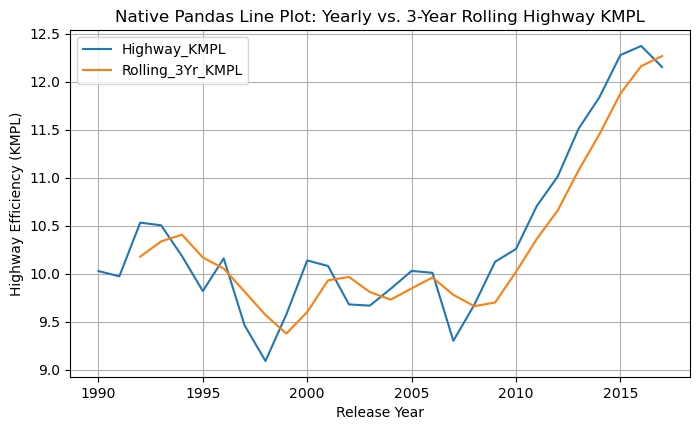

In [47]:
ax1 = yearly_trend[['Highway_KMPL', 'Rolling_3Yr_KMPL']].plot(
    kind='line',
    figsize=(8, 4.5),
    grid=True,
    title='Native Pandas Line Plot: Yearly vs. 3-Year Rolling Highway KMPL',
    xlabel='Release Year',
    ylabel='Highway Efficiency (KMPL)'
)

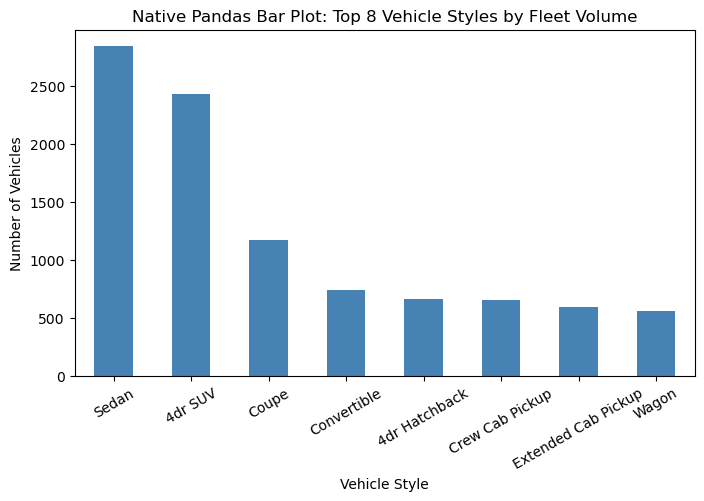

In [48]:
ax2 = style_agg.head(8)['Count'].plot.bar(
    figsize=(8, 4.5),
    color='steelblue',
    rot=30,
    title='Native Pandas Bar Plot: Top 8 Vehicle Styles by Fleet Volume',
    xlabel='Vehicle Style',
    ylabel='Number of Vehicles'
)

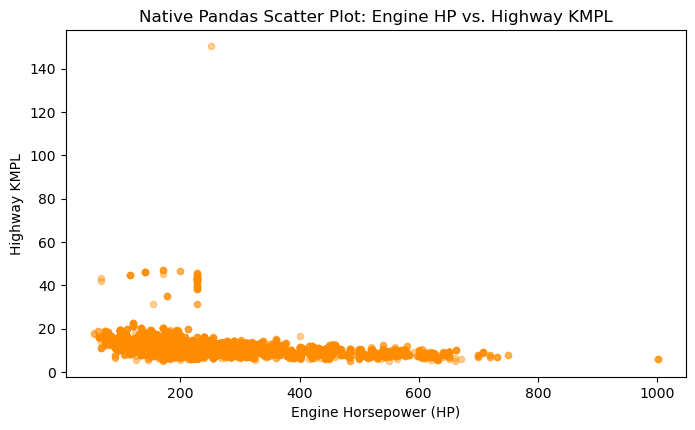

In [49]:
ax3 = df_clean.plot.scatter(
    x='Engine HP',
    y='Highway_KMPL',
    alpha=0.4,
    figsize=(8, 4.5),
    color='darkorange',
    title='Native Pandas Scatter Plot: Engine HP vs. Highway KMPL',
    xlabel='Engine Horsepower (HP)',
    ylabel='Highway KMPL'
)

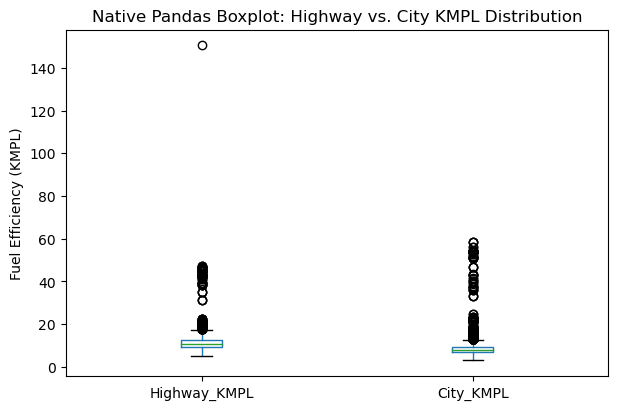

In [50]:
ax4 = df_clean[['Highway_KMPL', 'City_KMPL']].plot.box(
    figsize=(7, 4.5),
    title='Native Pandas Boxplot: Highway vs. City KMPL Distribution',
    ylabel='Fuel Efficiency (KMPL)'
)

# Reset only the display options we modified to avoid deprecated config warnings
pd.reset_option('^display\.')

**Interpretation (Task 7b Visualizations):**
1. **Line Plot:** The 3-year rolling window smooths annual variance and clearly highlights the post-2010 upward trend in highway fuel efficiency (rising from ~10.0 KMPL to >12.2 KMPL).
2. **Bar Chart:** Sedans (2,843 unique units) and 4dr SUVs (2,434 unique units) dominate the fleet distribution.
3. **Scatter Plot & Boxplot:** Confirm an inverse relationship between Engine HP and Highway KMPL, while the boxplot illustrates a higher median and wider upper-tail outlier range (electric vehicles reaching ~150 KMPL equivalent) for highway efficiency compared to city driving.